In [1]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import Tensor, nn
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F

import xarray as xr
import random
from dataclasses import dataclass
from typing import Iterable
import csv
from collections import defaultdict
from pathlib import Path

from itertools import combinations
from matplotlib.patches import Patch


In [2]:
def set_seed(seed: int) -> None:
    """Seed supported random number generators for reproducible experiments."""
    if seed < 0:
        raise ValueError("seed must be non-negative")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

# Introduction

## Brief

1. Find some weather/climate data. Be
adventurous!

2. Get an LLM to help you write
PyTorch code that runs a
transformer (use time series data) or
an autoencoder (use gridded data)

3. Compare both against a suitable
baseline and evaluate performance

4. Submit your presentation and
Python notebook to the Google
Form.

5. Present in your group for 5 minutes


__We have chosen to use a variational autoencoder to investigate ocean states__

# Data Visualisation

In [3]:
pacific_centre_long = 200
pacific_centre_lat = -2
v_box_size = 128
h_box_size = 256

(528, 513, 1025)

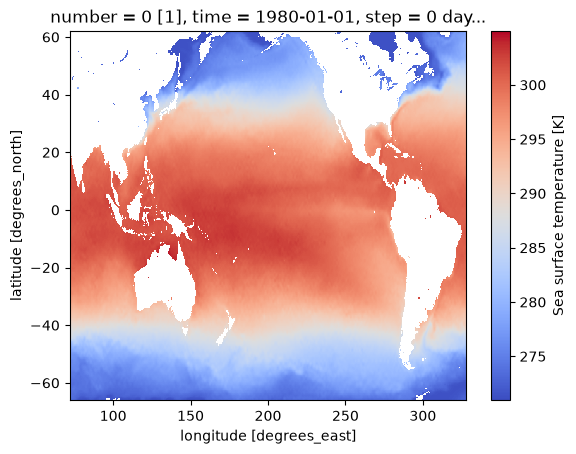

In [4]:
ds = xr.open_dataset('data/data.grib')
ds_pacific = ds.sel(latitude=slice(pacific_centre_lat + v_box_size/2, pacific_centre_lat - v_box_size/2), longitude=slice(pacific_centre_long - h_box_size/2, pacific_centre_long + h_box_size/2))
ds_pacific.sst[0].plot(cmap="coolwarm")
ds_pacific.sst.shape

(528, 256, 256)

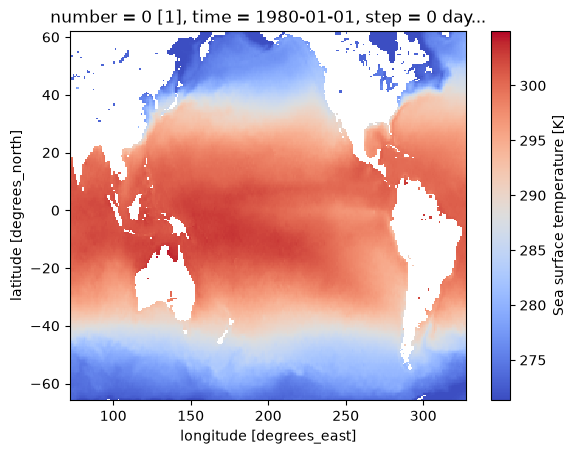

In [5]:
ds_pacific = ds_pacific.coarsen(latitude=2, longitude=4, boundary="trim").mean()
ds_pacific.sst[0].plot(cmap="coolwarm")
ds_pacific.sst.shape

In [6]:
ds_pacific.sst.shape

(528, 256, 256)

In [7]:
ds_mean = ds_pacific.sst.mean(dim=['latitude', 'longitude'])
ds_pacific_anomaly = ds_pacific - ds_mean

While cleaning the data I was unexpectedly reminded of climate change when observing the mean SST

Text(0.5, 0, 'Time (Months since 1981-01-01)')

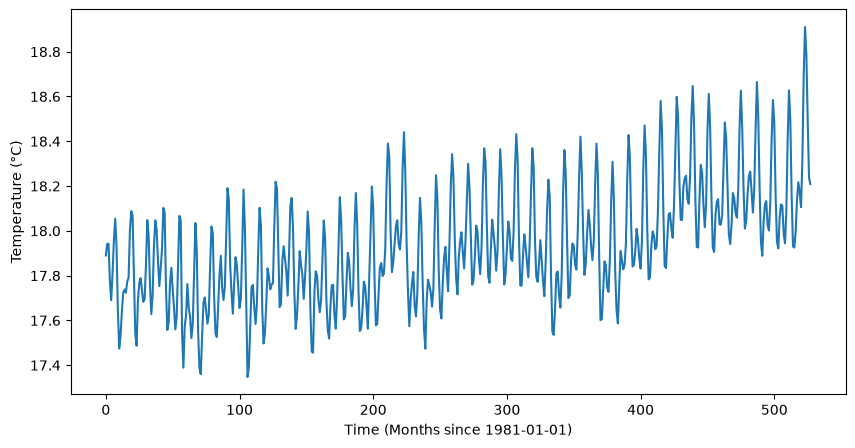

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ds_mean -273.15, label='Mean SST')
ax.set_ylabel('Temperature (°C)')
ax.set_xlabel('Time (Months since 1981-01-01)')

Text(0.5, 1.0, 'Pacific Sea Surface Temperature anomaly (SSTA) at time step 500')

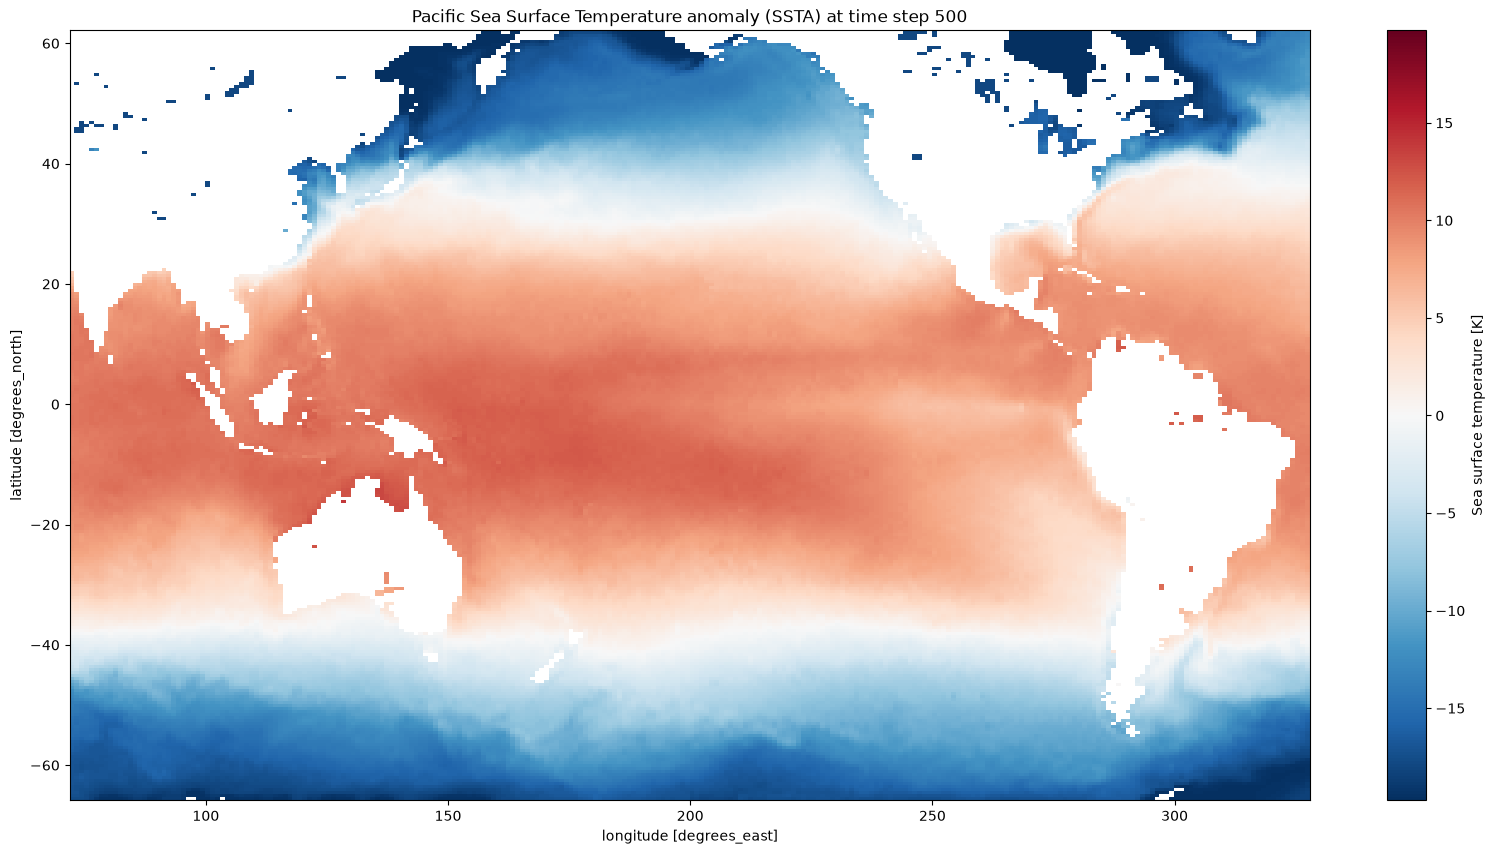

In [9]:
fig2, ax2 = plt.subplots(figsize=(20, 10))
ds_pacific_anomaly.sst[0].plot(ax=ax2)
ax2.set_title('Pacific Sea Surface Temperature anomaly (SSTA) at time step 500')

From the above, we will chose a bounding box of $$\text{latitude} \in [-66,62]$$
and 
$$\text{longitude} \in [72,328]$$

Giving image dimensions of 
$$1025 \times 513$$

which is then non-uniformly coarsened to $$256 \times 256$$

In [10]:
@dataclass # dataclass decorator
class Standardizer:  
    """Training-set normalization parameters."""

    mean: float
    std: float

    def transform(self, values: np.ndarray) -> np.ndarray:
        return (values - self.mean) / self.std

    def inverse_transform(self, values: np.ndarray) -> np.ndarray:
        return values * self.std + self.mean


In [11]:
def prepare_sst(
    dataset: xr.Dataset, 
    *,
    centre_longitude: float = 200,
    centre_latitude: float = -2,
    latitude_size: int = 128,
    longitude_size: int = 256,
    latitude_coarsen: int = 2,
    longitude_coarsen: int = 4,
    #takes in the data and parameters determined previously
) -> xr.DataArray:
    
    """Crop, coarsen, and remove the monthly SST climatology."""

    sst = dataset["sst"].sel( #select sea surface temp
        latitude=slice(
            centre_latitude + latitude_size / 2,
            centre_latitude - latitude_size / 2,
        ),
        longitude=slice(
            centre_longitude - longitude_size / 2,
            centre_longitude + longitude_size / 2,
        ), #apply slices to determine bounding box
    )

    sst = sst.coarsen(
        latitude=latitude_coarsen, #coarsen x2: 512 -> 256
        longitude=longitude_coarsen, #coarsen x4: 1024 -> 256
        boundary="trim",
    ).mean()
    
    #print(sst.shape)
    anomaly = sst.groupby("time.month") - sst.groupby("time.month").mean("time") # monthly_value-monthly_mean = monthly_anomaly
    return anomaly.transpose("time", "latitude", "longitude") #return sst anomaly with time as first dimension, latitude second, longitude third


In [12]:
def make_dataloaders(
    data: xr.DataArray,
    *,
    validation_fraction: float = 0.2,
    batch_size: int = 16,
    seed: int = 0,
    #takes in data and hyperparameter
) -> tuple[DataLoader[tuple[Tensor]], DataLoader[tuple[Tensor]], Standardizer, int]:
    
    """Create chronological train/validation loaders and fit normalization on train."""

    if not 0 < validation_fraction < 1: # validation fraction check
        raise ValueError("validation_fraction must be between 0 and 1")
    if data.dims != ("time", "latitude", "longitude"): # check for data dimensions
        raise ValueError("data must have time, latitude, and longitude dimensions")


    values = np.asarray(data.values, dtype=np.float32) # convert to numpy array of float32
    split = int(values.shape[0] * (1 - validation_fraction)) # determine where data will be split into training and validation


    if split < 1 or split == values.shape[0]: # data check to ensure there are enough time steps for both training and validation
        raise ValueError("data must contain enough time steps for both splits")
    
    training_values = values[:split] # splits out training
    finite_training_values = training_values[np.isfinite(training_values)] # filters out non-finite values

    if finite_training_values.size == 0: # no finite values check
        raise ValueError("training data contains no finite SST values")
    
    mean = float(finite_training_values.mean())
    std = float(finite_training_values.std())

    if not np.isfinite(std) or std == 0: # check for finite standard deviation
        raise ValueError(
            "training data must have finite SST values with non-zero variation"
        )
    
    standardizer = Standardizer(mean, std) # run standardiser class
    normalized = standardizer.transform(values)  #normalised values

    # Land cells are commonly NaN in SST products. Zero is the climatological
    # anomaly after standardization and keeps those cells from poisoning loss.
    normalized = np.nan_to_num(normalized, nan=0.0, posinf=0.0, neginf=0.0).astype(
        np.float32
    )
    
    tensors = torch.from_numpy(normalized[:, None]) # create tensor from normalized values, add channel dimension
    train = TensorDataset(tensors[:split])  # create tensor dataset for training data
    validation = TensorDataset(tensors[split:])  # create tensor dataset for validation data
    generator = torch.Generator().manual_seed(seed) # create generator for reproducibility
    
    return (
        DataLoader(train, batch_size=batch_size, shuffle=True, generator=generator), # torch dataloader for training data, shuffles data for each epoch
        DataLoader(validation, batch_size=batch_size, shuffle=False), # torch dataloader for validation data, does not shuffle data
        standardizer, # return standardizer for inverse transform
        split, # return split index for training and validation data
    )

<h1>Variational Convolutional Autoencoder<h1>

In [13]:
class ConvVAE(nn.Module):
    """Convolutional VAE for 256 x 256 single-channel SST fields."""

    def __init__(self, latent_dim: int = 16) -> None: #Assumes latent dim of 16
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.LeakyReLU(0.2), # leaky relu used to avoid dead neurons
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 3, stride=2, padding=1), nn.LeakyReLU(0.2),
            nn.Conv2d(256, 512, 3, stride=2, padding=1), nn.LeakyReLU(0.2),
        )

        self.mu = nn.Linear(512 * 8 * 8, latent_dim) # linear layer to map encoder output to mean of latent distribution
        self.logvar = nn.Linear(512 * 8 * 8, latent_dim) # linear layer to map encoder output to log variance of latent distribution
        self.decoder_input = nn.Linear(latent_dim, 512 * 8 * 8) # linear layer to map latent space to decoder input
        
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(512, 256, 3, stride=2, padding=1, output_padding=1), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(256, 128, 3, stride=2, padding=1, output_padding=1), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(128, 64, 3, stride=2, padding=1, output_padding=1), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1),
        )

    def encode(self, x: Tensor) -> tuple[Tensor, Tensor]:
        hidden = self.encoder(x).flatten(1)
        return self.mu(hidden), self.logvar(hidden) # return mean and log variance of latent distribution

    def decode(self, z: Tensor) -> Tensor:
        hidden = self.decoder_input(z).view(-1, 512, 8, 8)
        return self.decoder(hidden) # return reconstructed output

    def forward(self, x: Tensor) -> tuple[Tensor, Tensor, Tensor]: #forward pass, returns reconstructed output, mean, and log variance of latent distribution
        mu, logvar = self.encode(x)
        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std
        return self.decode(z), mu, logvar 


In [14]:

def vae_loss(
    reconstruction: Tensor,
    target: Tensor,
    mu: Tensor,
    logvar: Tensor,
    *,
    beta: float = 1e-3,
    #takes inputs of vae output, target, mean, log variance, and beta hyperparameter
) -> tuple[Tensor, Tensor, Tensor]:
    
    """Return total, reconstruction, and KL losses averaged per sample."""

    reconstruction_loss = nn.functional.mse_loss(reconstruction, target, reduction="mean")
    kl_loss = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(dim=1).mean()
    
    return reconstruction_loss + beta * kl_loss, reconstruction_loss, kl_loss


In [15]:
def _run_epoch(
    model: ConvVAE,
    loader: Iterable[tuple[Tensor]],
    device: torch.device,
    *,
    beta: float,
    optimizer: torch.optim.Optimizer | None,
    # takes in model, dataloader, device, beta hyperparameter, and optimizer
) -> dict[str, float]:
    
    training = optimizer is not None # if optimizer is not None, then we are training, otherwise we are validating

    model.train(training) # run one forward and backprop

    totals = {"loss": 0.0, "reconstruction": 0.0, "kl": 0.0} 
    samples = 0
    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for (batch,) in loader: 
            batch = batch.to(device)
            mu, logvar = model.encode(batch) # encode the batch to get mean and log variance of latent distribution

            if training: # if we are training, we sample from the latent distribution using the reparameterization trick
                std = torch.exp(0.5 * logvar)
                latent = mu + torch.randn_like(std) * std
            
            else:
            
                latent = mu # if we are validating, we use the mean of the latent distribution as the latent vector
            
            reconstruction = model.decode(latent) # decode the latent vector to get the reconstructed output
            
            loss, reconstruction_loss, kl_loss = vae_loss(
                reconstruction, batch, mu, logvar, beta=beta
            )
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
                loss.backward() # backpropagate the loss
                optimizer.step() # update the model parameters using the optimizer
                
            count = batch.shape[0]
            samples += count
            totals["loss"] += loss.item() * count
            totals["reconstruction"] += reconstruction_loss.item() * count
            totals["kl"] += kl_loss.item() * count

    return {name: value / samples for name, value in totals.items()}

In [16]:
def train_conv_vae(
    model: ConvVAE,
    train_loader: DataLoader[tuple[Tensor]],
    validation_loader: DataLoader[tuple[Tensor]],
    *,
    epochs: int = 100,
    learning_rate: float = 1e-3,
    beta: float = 1e-3,
    weight_decay: float = 1e-5,
    patience: int = 15,
    min_delta: float = 1e-5,
    seed: int | None = None,
    device: str | torch.device | None = None,
) -> list[dict[str, float]]:

    
    """Train a VAE, stopping and restoring the best validation checkpoint."""

    
    if epochs < 1:
        raise ValueError("epochs must be positive")
    if patience < 1:
        raise ValueError("patience must be positive")
    if min_delta < 0:
        raise ValueError("min_delta must not be negative")
    if seed is not None:
        set_seed(seed)
    target_device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))


    model.to(target_device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    ) # use Adam optimizer with learning rate and weight decay hyperparameters

    history: list[dict[str, float]] = [] # initialize history list to store training and validation metrics for each epoch
    best_validation_loss = float("inf")
    best_state = {
        name: parameter.detach().cpu().clone() # store the best model state based on validation loss
        for name, parameter in model.state_dict().items()
    }


    epochs_without_improvement = 0
    for epoch in range(epochs): # loop through epochs
        train_metrics = _run_epoch(
            model, train_loader, target_device, beta=beta, optimizer=optimizer
        )
        validation_metrics = _run_epoch(
            model, validation_loader, target_device, beta=beta, optimizer=None
        )
        history.append(
            {
                "epoch": float(epoch + 1),
                **{f"train_{key}": value for key, value in train_metrics.items()},
                **{f"validation_{key}": value for key, value in validation_metrics.items()},
            }
        )
        if validation_metrics["loss"] < best_validation_loss - min_delta: # check if validation loss has improved by at least min_delta
            best_validation_loss = validation_metrics["loss"]
            best_state = {
                name: parameter.detach().cpu().clone()
                for name, parameter in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        print(
            f"epoch {epoch + 1:03d}/{epochs}: "
            f"train={train_metrics['loss']:.5f}, "
            f"validation={validation_metrics['loss']:.5f}"
        )
        if epochs_without_improvement >= patience:
            print(f"early stopping after {epoch + 1} epochs")
            break


    model.load_state_dict(best_state)
    return history

In [17]:
@torch.no_grad() # decorator to disable gradient calculation for inference

def encode_latents(
    model: ConvVAE,
    data: xr.DataArray,
    standardizer: Standardizer,
    *,
    batch_size: int = 32,
    device: str | torch.device | None = None,
) -> xr.Dataset:

    
    """Encode every SST field and return latent means indexed by timestamp."""


    target_device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))

    model.to(target_device)
    
    model.eval()
    
    values = standardizer.transform(np.asarray(data.values, dtype=np.float32))
    values = np.nan_to_num(values, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    loader = DataLoader(TensorDataset(torch.from_numpy(values[:, None])), batch_size=batch_size)
    latent_means: list[np.ndarray] = []
    
    for (batch,) in loader:
        mu, _ = model.encode(batch.to(target_device))
        latent_means.append(mu.cpu().numpy())
    
    latent = np.concatenate(latent_means, axis=0)
    
    coordinates = {"time": data.time, "latent": np.arange(model.latent_dim)}
    
    return xr.Dataset(
        {"latent_mean": (("time", "latent"), latent)},
        coords=coordinates,
    )

# Running the Model

In [18]:
BETA = 1e-4# choose beta 

In [19]:
seed = 42
set_seed(seed) # seed the random number generators for reproducibility


ds = xr.open_dataset("data/data.grib") # take in data
sst_anomaly = prepare_sst(ds) # prepare data for training

train_loader, validation_loader, standardizer, split = make_dataloaders(
    sst_anomaly, batch_size=16, validation_fraction=0.2, seed=seed
) # make the dataloaders from the prepared data

In [20]:
values = sst_anomaly.values

print("Shape:", values.shape)
print("Finite values:", np.isfinite(values).sum())
print("NaN values:", np.isnan(values).sum())
print("Minimum:", np.nanmin(values))
print("Maximum:", np.nanmax(values))
print("Standard deviation:", np.nanstd(values))

Shape: (528, 256, 256)
Finite values: 27590112
NaN values: 7012896
Minimum: -13.294891
Maximum: 14.056061
Standard deviation: 0.66013217


In [21]:
model = ConvVAE(latent_dim=16) # make model with 16 latent dims

history = train_conv_vae(
    model,
    train_loader,
    validation_loader,
    epochs=100,
    beta=BETA,
    learning_rate=3e-4,
    weight_decay=1e-4,
    patience=10,
    seed=seed,
) # train the model

latents = encode_latents(model, sst_anomaly, standardizer) # encode the latents from the trained model and the SST anomaly data

epoch 001/100: train=0.81882, validation=0.96592
epoch 002/100: train=0.68893, validation=0.80347
epoch 003/100: train=0.58120, validation=0.70815
epoch 004/100: train=0.48219, validation=0.64228
epoch 005/100: train=0.43381, validation=0.62782
epoch 006/100: train=0.40457, validation=0.61082
epoch 007/100: train=0.38418, validation=0.61774
epoch 008/100: train=0.36815, validation=0.61696
epoch 009/100: train=0.35918, validation=0.62852
epoch 010/100: train=0.34677, validation=0.63622
epoch 011/100: train=0.33543, validation=0.62525
epoch 012/100: train=0.32497, validation=0.64455
epoch 013/100: train=0.31600, validation=0.65525
epoch 014/100: train=0.30944, validation=0.68901
epoch 015/100: train=0.30455, validation=0.66304
epoch 016/100: train=0.29586, validation=0.67908
early stopping after 16 epochs


Text(0.5, 1.0, 'Training and Validation Loss')

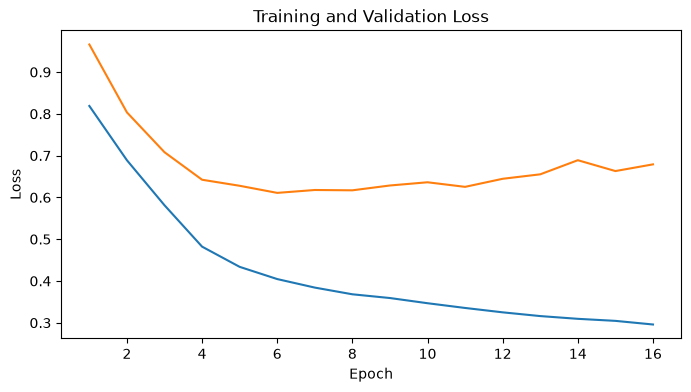

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in ["train_loss", "validation_loss"]:
    ax.plot([entry["epoch"] for entry in history], [entry[name] for entry in history], label=name)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Training and Validation Loss")

# Using learned latent dimesions for classification
Importantly, the model has been trained before the classification data is is ever loaded into the notebook. Thus if the model shows the ability to classify el nino years then the learned latent dimensions have picked out some feature that is important to the ENSO

Below, each pair of latent vectors are plotted in order to determine which pair most effectively captures the features of an El Nino month

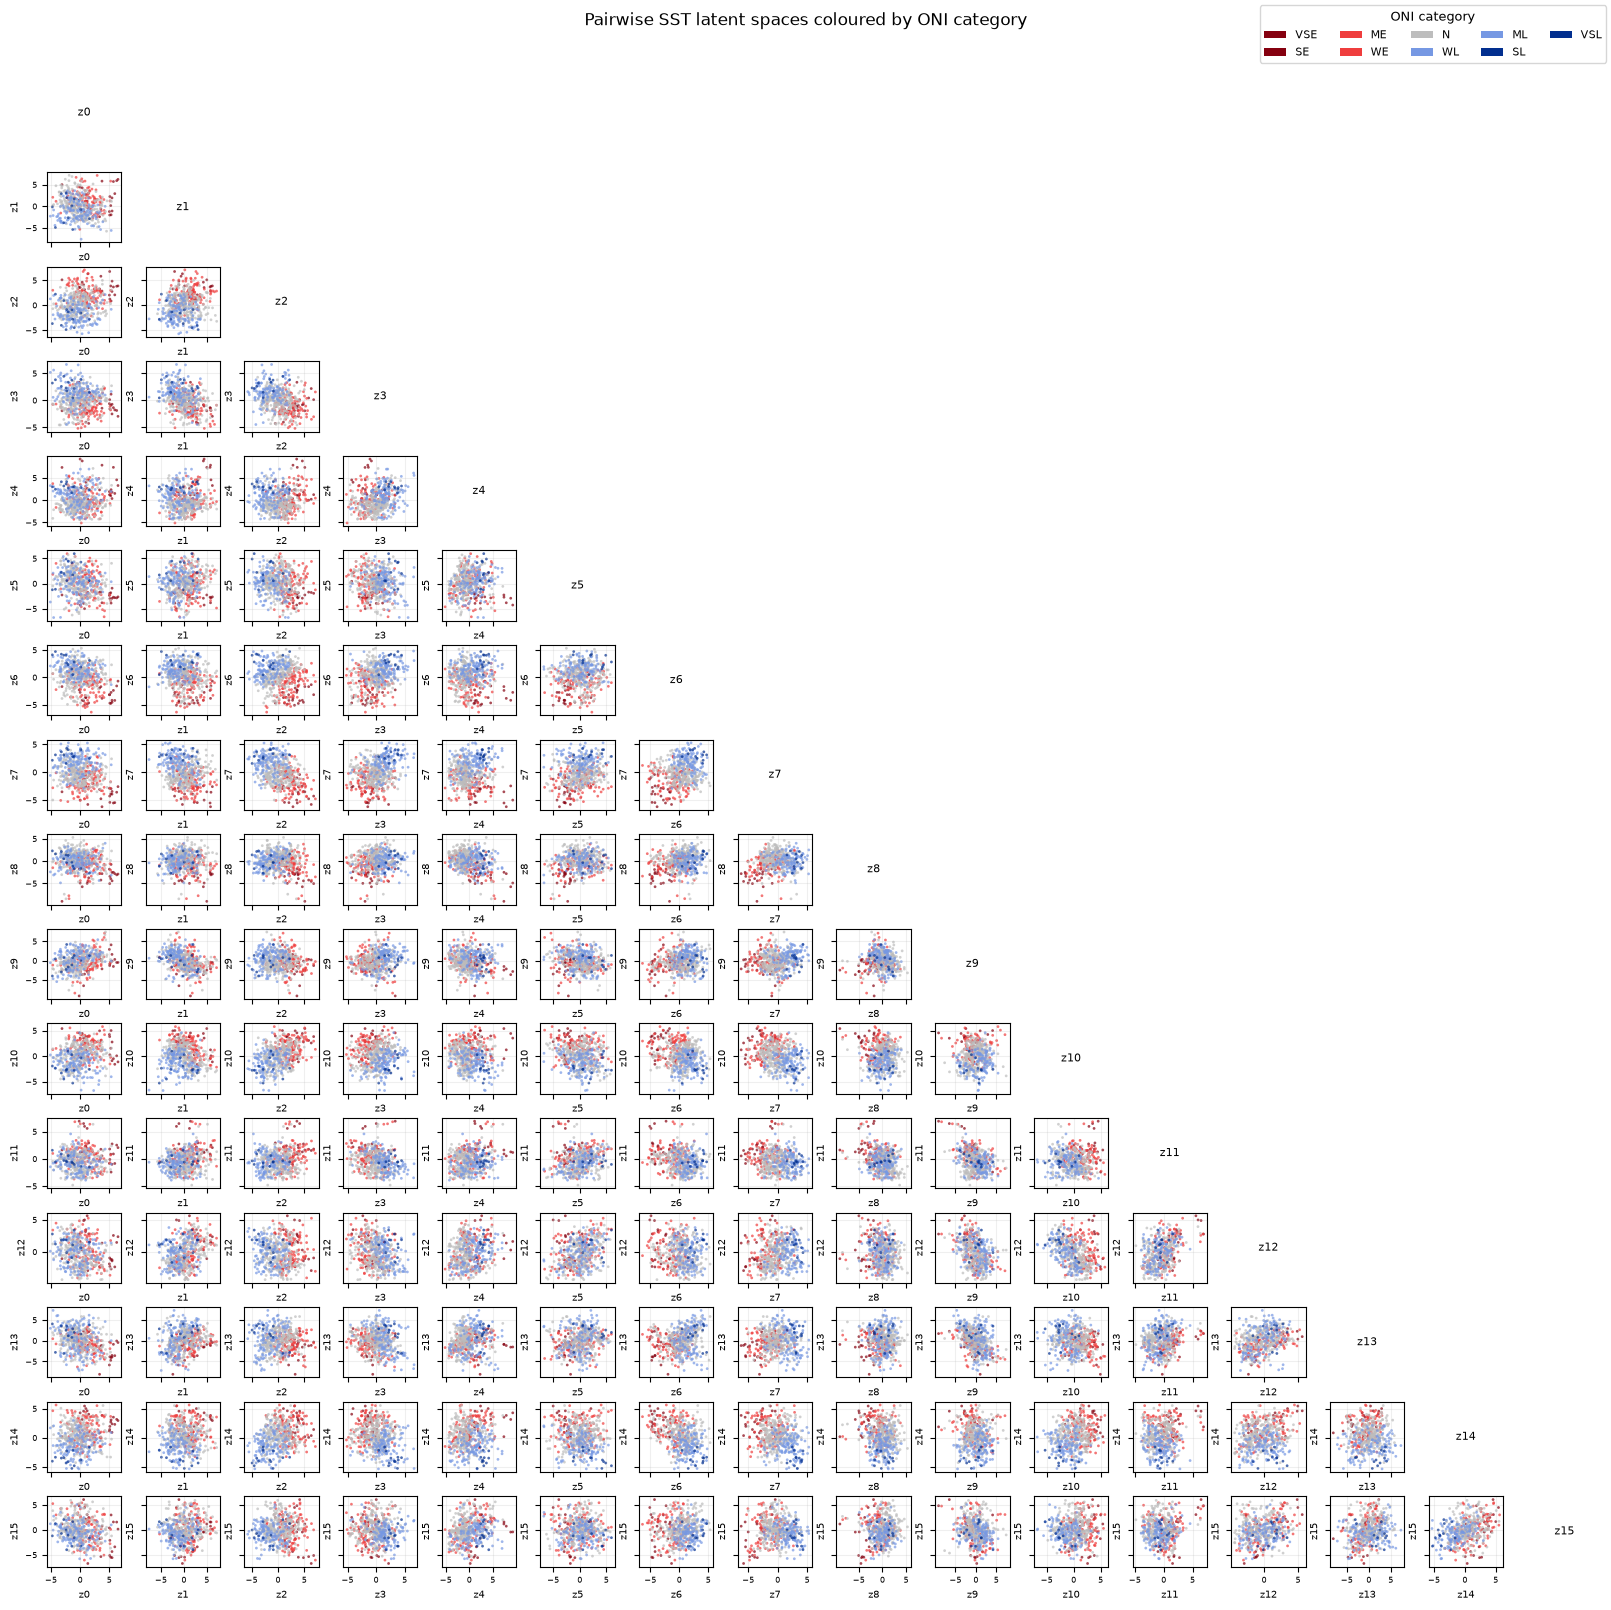

Matched 528 of 528 latent months to ONI categories


In [23]:
oni_by_date = {}
with Path("data/oni.csv").open(newline="") as oni_file:
    for row in csv.DictReader(oni_file):
        oni_by_date[row["date"]] = row["category"] # create a dictionary mapping dates to ONI categories

latent_dates = latents.time.dt.strftime("%Y-%m-%d").values
categories = np.array([oni_by_date.get(date, "Unlabelled") for date in latent_dates])
matched = categories != "Unlabelled"

category_colours = {
    "VSE": "#85000f",
    "SE": "#85000f",
    "ME": "#ef3d3d",
    "WE": "#ef3d3d",
    "N": "#bdbdbd",
    "WL": "#7698e3",
    "ML": "#7698e3",
    "SL": "#022f8f",
    "VSL": "#022f8f",
    
}

latent_values = latents.latent_mean.values[matched]
latent_dimension = latent_values.shape[1]
fig, axes = plt.subplots(
    latent_dimension,
    latent_dimension,
    figsize=(16, 16),
    sharex="col",
    sharey="row",
    squeeze=False,
)

for row, column in combinations(range(latent_dimension), 2):
    ax = axes[column, row]
    for category, colour in category_colours.items():
        selected = categories[matched] == category
        ax.scatter(
            latent_values[selected, row],
            latent_values[selected, column],
            color=colour,
            s=4,
            alpha=0.7,
            edgecolors="none",
            rasterized=True,
        )
    ax.set_xlabel(f"z{row}", fontsize=7)
    ax.set_ylabel(f"z{column}", fontsize=7)
    ax.tick_params(labelsize=6)
    ax.grid(alpha=0.2)

for index in range(latent_dimension):
    axes[index, index].text(
        0.5,
        0.5,
        f"z{index}",
        ha="center",
        va="center",
        fontsize=8,
        transform=axes[index, index].transAxes,
    )
    axes[index, index].set_axis_off()

for row in range(latent_dimension):
    for column in range(row + 1, latent_dimension):
        axes[row, column].set_visible(False)

legend_handles = [
    Patch(facecolor=colour, label=category)
    for category, colour in category_colours.items()
]
fig.legend(
    handles=legend_handles,
    title="ONI category",
    loc="upper right",
    ncol=5,
    fontsize=8,
    title_fontsize=9,
)
fig.suptitle("Pairwise SST latent spaces coloured by ONI category", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97), pad=0.3)
plt.show()

print(f"Matched {matched.sum()} of {len(matched)} latent months to ONI categories")

<span style="color:red">Using the above image, choose a pair of latent dimensions to display that most effectively categorise the data</span>

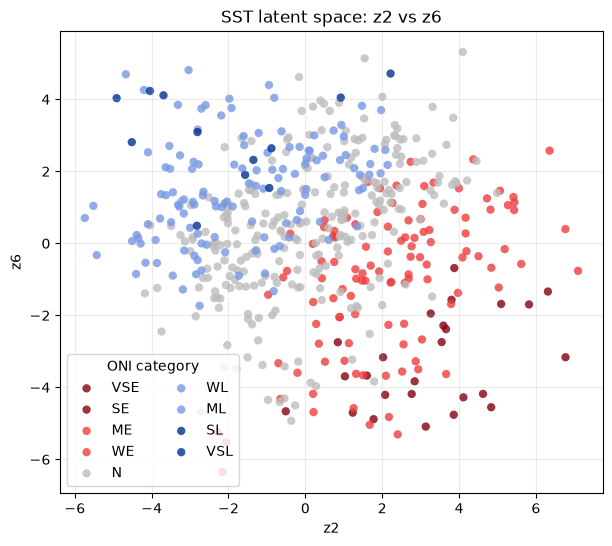

In [24]:
# Choose one pair of latent vectors to plot.
x_latent = 2
y_latent = 6

if not (0 <= x_latent < latents.sizes["latent"]):
    raise ValueError(f"x_latent must be between 0 and {latents.sizes['latent'] - 1}")
if not (0 <= y_latent < latents.sizes["latent"]):
    raise ValueError(f"y_latent must be between 0 and {latents.sizes['latent'] - 1}")
if x_latent == y_latent:
    raise ValueError("x_latent and y_latent must be different")

fig, ax = plt.subplots(figsize=(7, 6))
for category, colour in category_colours.items():
    selected = matched & (categories == category)
    ax.scatter(
        latents.latent_mean.values[selected, x_latent],
        latents.latent_mean.values[selected, y_latent],
        color=colour,
        label=category,
        alpha=0.8,
        edgecolors="none",
    )

ax.set_xlabel(f"z{x_latent}")
ax.set_ylabel(f"z{y_latent}")
ax.set_title(f"SST latent space: z{x_latent} vs z{y_latent}")
ax.legend(title="ONI category", ncol=2)
ax.grid(alpha=0.25)
plt.show()


<span style="color:red"> Choose a sample index from 0 to 528 </span>

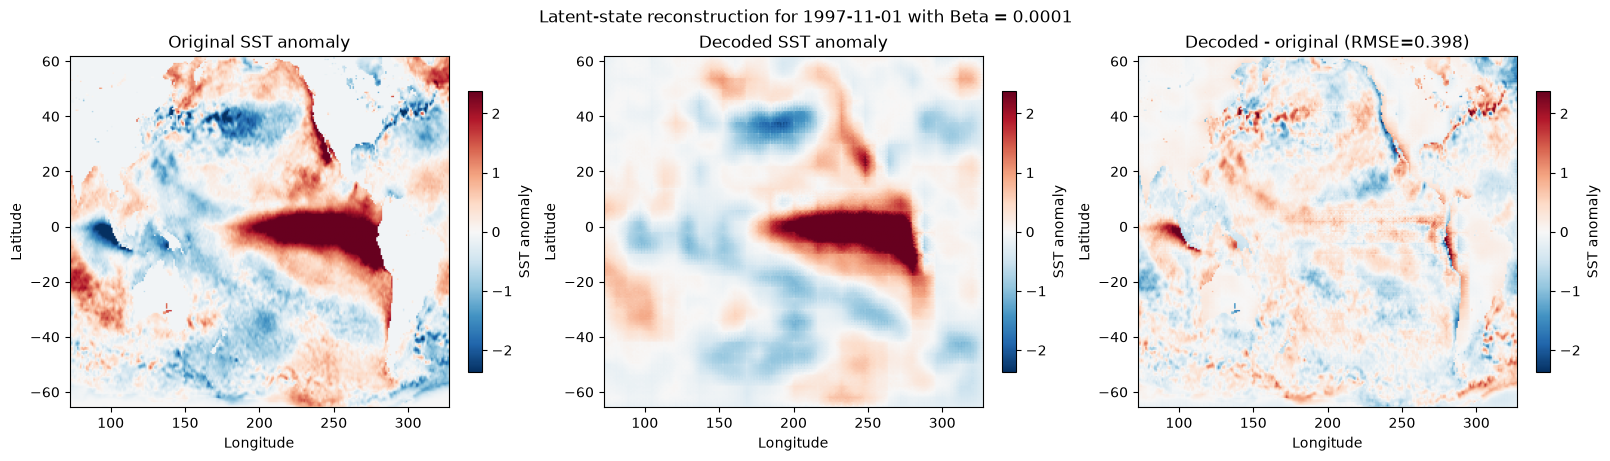

latent vector: [ 3.744  5.807  2.845 -1.455  7.862 -3.822 -3.833 -6.197 -2.819 -2.135
  1.229  0.539  1.366 -1.163  3.834  0.745]


In [25]:
rmses = np.array([])
indices = np.array([])
# Decode one latent state and compare it with the original SST anomaly.
sample_index = 214
custom_latent = None  # Or set a length-16 array to decode a chosen latent state.
indices = np.append(indices, sample_index)

if not 0 <= sample_index < sst_anomaly.sizes["time"]:
    raise ValueError(
        f"sample_index must be between 0 and {sst_anomaly.sizes['time'] - 1}"
    )
if custom_latent is not None and len(custom_latent) != model.latent_dim:
    raise ValueError(f"custom_latent must contain {model.latent_dim} values")

device = next(model.parameters()).device
original_normalized = standardizer.transform(
    np.asarray(sst_anomaly.isel(time=sample_index).values, dtype=np.float32)
)
original_normalized = np.nan_to_num(
    original_normalized, nan=0.0, posinf=0.0, neginf=0.0
)
input_tensor = torch.from_numpy(original_normalized[None, None]).to(device)

model.eval()
with torch.no_grad():
    encoded_mu, _ = model.encode(input_tensor)
    latent_tensor = (
        torch.as_tensor(custom_latent, dtype=torch.float32, device=device)[None]
        if custom_latent is not None
        else encoded_mu
    )
    decoded_normalized = model.decode(latent_tensor)[0, 0].cpu().numpy()

original_anomaly = standardizer.inverse_transform(original_normalized)
decoded_anomaly = standardizer.inverse_transform(decoded_normalized)
error = decoded_anomaly - original_anomaly
date = str(sst_anomaly.time.isel(time=sample_index).values)[:10]
latent_values = latent_tensor[0].detach().cpu().numpy()
rmse = float(np.sqrt(np.nanmean(error**2)))
rmses = np.append(rmses, rmse)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
image_extent = [
    float(sst_anomaly.longitude.min()),
    float(sst_anomaly.longitude.max()),
    float(sst_anomaly.latitude.min()),
    float(sst_anomaly.latitude.max()),
]
plots = [
    (original_anomaly, "Original SST anomaly"),
    (decoded_anomaly, "Decoded SST anomaly"),
    (error, f"Decoded - original (RMSE={rmse:.3f})"),
]
common_limit = np.nanpercentile(
    np.concatenate([np.abs(image).ravel() for image, _ in plots]),
    98,
)
for axis, (image, title) in zip(axes, plots):
    im = axis.imshow(
        image,
        origin="upper",
        extent=image_extent,
        cmap="RdBu_r",
        vmin=-common_limit,
        vmax=common_limit,
        aspect="auto",
    )
    axis.set_title(title)
    axis.set_xlabel("Longitude")
    axis.set_ylabel("Latitude")
    fig.colorbar(im, ax=axis, shrink=0.8, label="SST anomaly")
fig.suptitle(f"Latent-state reconstruction for {date} with Beta = {BETA}")
plt.show()
print("latent vector:", np.round(latent_values, 3))


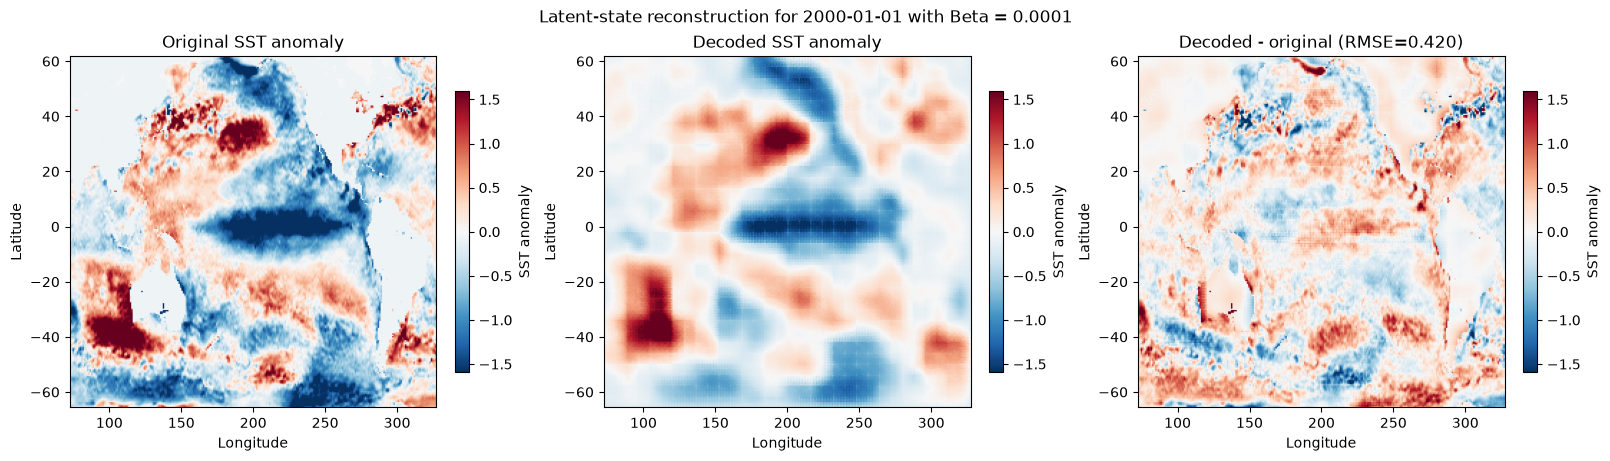

latent vector: [ 0.167 -7.598 -2.752  0.6    3.205  1.393 -1.734  2.278 -0.408  0.632
 -6.671 -0.618  1.082  0.585 -2.4    0.18 ]


In [26]:
# Decode one latent state and compare it with the original SST anomaly.
sample_index = 240
custom_latent = None  # Or set a length-16 array to decode a chosen latent state.
indices = np.append(indices, sample_index)
if not 0 <= sample_index < sst_anomaly.sizes["time"]:
    raise ValueError(
        f"sample_index must be between 0 and {sst_anomaly.sizes['time'] - 1}"
    )
if custom_latent is not None and len(custom_latent) != model.latent_dim:
    raise ValueError(f"custom_latent must contain {model.latent_dim} values")

device = next(model.parameters()).device
original_normalized = standardizer.transform(
    np.asarray(sst_anomaly.isel(time=sample_index).values, dtype=np.float32)
)
original_normalized = np.nan_to_num(
    original_normalized, nan=0.0, posinf=0.0, neginf=0.0
)
input_tensor = torch.from_numpy(original_normalized[None, None]).to(device)

model.eval()
with torch.no_grad():
    encoded_mu, _ = model.encode(input_tensor)
    latent_tensor = (
        torch.as_tensor(custom_latent, dtype=torch.float32, device=device)[None]
        if custom_latent is not None
        else encoded_mu
    )
    decoded_normalized = model.decode(latent_tensor)[0, 0].cpu().numpy()

original_anomaly = standardizer.inverse_transform(original_normalized)
decoded_anomaly = standardizer.inverse_transform(decoded_normalized)
error = decoded_anomaly - original_anomaly
date = str(sst_anomaly.time.isel(time=sample_index).values)[:10]
latent_values = latent_tensor[0].detach().cpu().numpy()
rmse = float(np.sqrt(np.nanmean(error**2)))
rmses = np.append(rmses, rmse)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
image_extent = [
    float(sst_anomaly.longitude.min()),
    float(sst_anomaly.longitude.max()),
    float(sst_anomaly.latitude.min()),
    float(sst_anomaly.latitude.max()),
]
plots = [
    (original_anomaly, "Original SST anomaly"),
    (decoded_anomaly, "Decoded SST anomaly"),
    (error, f"Decoded - original (RMSE={rmse:.3f})"),
]
common_limit = np.nanpercentile(
    np.concatenate([np.abs(image).ravel() for image, _ in plots]),
    98,
)
for axis, (image, title) in zip(axes, plots):
    im = axis.imshow(
        image,
        origin="upper",
        extent=image_extent,
        cmap="RdBu_r",
        vmin=-common_limit,
        vmax=common_limit,
        aspect="auto",
    )
    axis.set_title(title)
    axis.set_xlabel("Longitude")
    axis.set_ylabel("Latitude")
    fig.colorbar(im, ax=axis, shrink=0.8, label="SST anomaly")
fig.suptitle(f"Latent-state reconstruction for {date} with Beta = {BETA}")
plt.show()
print("latent vector:", np.round(latent_values, 3))


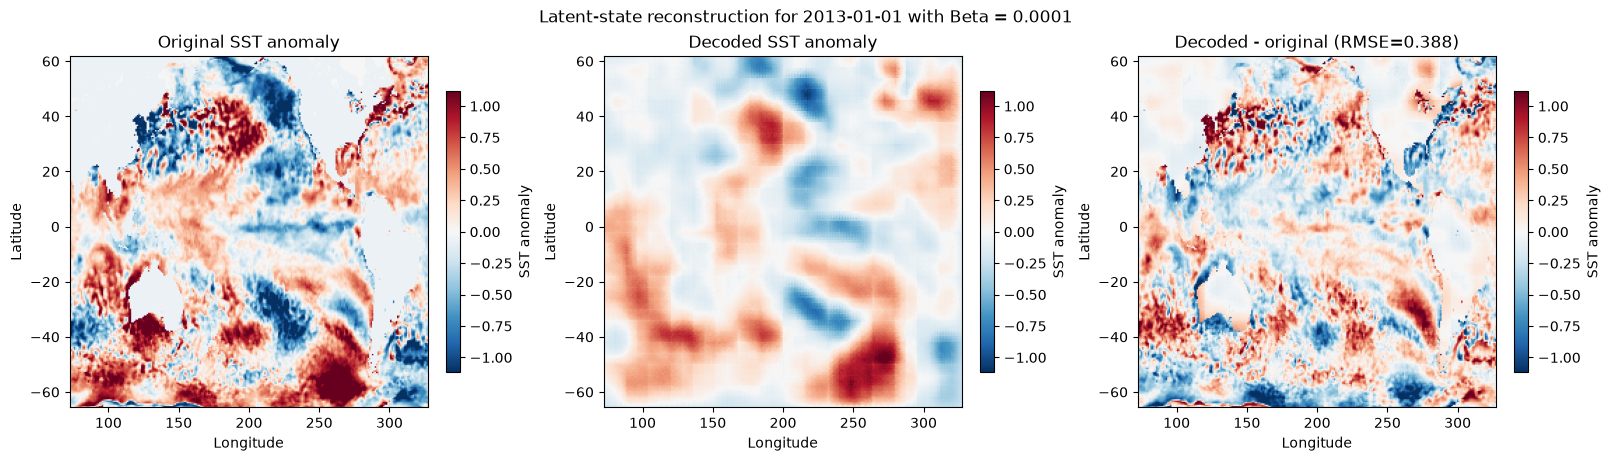

latent vector: [ 0.821 -3.52  -2.098  0.421 -0.75   1.285  2.668 -2.037 -2.942 -2.215
  3.015  0.318 -2.703  2.474 -0.147  1.87 ]


In [27]:
# Decode one latent state and compare it with the original SST anomaly.
sample_index = 396
custom_latent = None  # Or set a length-16 array to decode a chosen latent state.
indices = np.append(indices, sample_index)
if not 0 <= sample_index < sst_anomaly.sizes["time"]:
    raise ValueError(
        f"sample_index must be between 0 and {sst_anomaly.sizes['time'] - 1}"
    )
if custom_latent is not None and len(custom_latent) != model.latent_dim:
    raise ValueError(f"custom_latent must contain {model.latent_dim} values")

device = next(model.parameters()).device
original_normalized = standardizer.transform(
    np.asarray(sst_anomaly.isel(time=sample_index).values, dtype=np.float32)
)
original_normalized = np.nan_to_num(
    original_normalized, nan=0.0, posinf=0.0, neginf=0.0
)
input_tensor = torch.from_numpy(original_normalized[None, None]).to(device)

model.eval()
with torch.no_grad():
    encoded_mu, _ = model.encode(input_tensor)
    latent_tensor = (
        torch.as_tensor(custom_latent, dtype=torch.float32, device=device)[None]
        if custom_latent is not None
        else encoded_mu
    )
    decoded_normalized = model.decode(latent_tensor)[0, 0].cpu().numpy()

original_anomaly = standardizer.inverse_transform(original_normalized)
decoded_anomaly = standardizer.inverse_transform(decoded_normalized)
error = decoded_anomaly - original_anomaly
date = str(sst_anomaly.time.isel(time=sample_index).values)[:10]
latent_values = latent_tensor[0].detach().cpu().numpy()
rmse = float(np.sqrt(np.nanmean(error**2)))
rmses = np.append(rmses, rmse)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
image_extent = [
    float(sst_anomaly.longitude.min()),
    float(sst_anomaly.longitude.max()),
    float(sst_anomaly.latitude.min()),
    float(sst_anomaly.latitude.max()),
]
plots = [
    (original_anomaly, "Original SST anomaly"),
    (decoded_anomaly, "Decoded SST anomaly"),
    (error, f"Decoded - original (RMSE={rmse:.3f})"),
]
common_limit = np.nanpercentile(
    np.concatenate([np.abs(image).ravel() for image, _ in plots]),
    98,
)
for axis, (image, title) in zip(axes, plots):
    im = axis.imshow(
        image,
        origin="upper",
        extent=image_extent,
        cmap="RdBu_r",
        vmin=-common_limit,
        vmax=common_limit,
        aspect="auto",
    )
    axis.set_title(title)
    axis.set_xlabel("Longitude")
    axis.set_ylabel("Latitude")
    fig.colorbar(im, ax=axis, shrink=0.8, label="SST anomaly")
fig.suptitle(f"Latent-state reconstruction for {date} with Beta = {BETA}")
plt.show()
print("latent vector:", np.round(latent_values, 3))


# PCA Baseline

In [28]:
plt.rcParams["figure.dpi"] = 110
N_COMPONENTS = 16 
set_seed(seed)

CATEGORY_COLOURS = {
    "VSE": "#85000f", "SE": "#85000f", "ME": "#ef3d3d",
    "WE": "#ef3d3d", "N": "#bdbdbd", "WL": "#7698e3",
    "ML": "#7698e3", "SL": "#022f8f", "VSL": "#022f8f",
}

The SVD is fitted on the first 80% of months only, matching the VAE's chronological training split. The remaining months are projected with the already-fitted PCA; they are not used to estimate the PCA mean or components. Missing SST cells are set to zero after applying the same train-fitted standardization as the VAE.

In [29]:
def fit_pca(training_matrix: np.ndarray, n_components: int) -> dict[str, np.ndarray]:
    """Fit PCA with SVD and return the mean, components, and variance diagnostics."""
    if training_matrix.ndim != 2:
        raise ValueError("training_matrix must be two-dimensional")
    if not 1 <= n_components <= min(training_matrix.shape):
        raise ValueError("n_components must not exceed either training dimension")
    mean = training_matrix.mean(axis=0)
    centered = training_matrix - mean
    _, singular_values, components = np.linalg.svd(centered, full_matrices=False)
    components = components[:n_components]
    explained_variance = singular_values[:n_components] ** 2 / (training_matrix.shape[0] - 1)
    total_variance = (singular_values**2).sum() / (training_matrix.shape[0] - 1)
    return {"mean": mean, "components": components, "explained_variance": explained_variance, "explained_variance_ratio": explained_variance / total_variance, "total_variance": np.array(total_variance)}


def project_pca(values: np.ndarray, pca: dict[str, np.ndarray]) -> np.ndarray:
    return (values - pca["mean"]) @ pca["components"].T


def reconstruct_pca(scores: np.ndarray, pca: dict[str, np.ndarray]) -> np.ndarray:
    return scores @ pca["components"] + pca["mean"]

### Prepare shared input

In [30]:
_, _, standardizer, split = make_dataloaders(sst_anomaly, batch_size=16, validation_fraction=0.2, seed=seed)

raw_values = np.asarray(sst_anomaly.values, dtype=np.float32)
normalized_values = standardizer.transform(raw_values)
normalized_values = np.nan_to_num(normalized_values, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

n_months, n_latitude, n_longitude = raw_values.shape
flat_values = normalized_values.reshape(n_months, -1)
train_values = flat_values[:split]
pca = fit_pca(train_values, N_COMPONENTS)
scores = project_pca(flat_values, pca)
reconstructed_normalized = reconstruct_pca(scores, pca)
reconstructed_anomaly = standardizer.inverse_transform(reconstructed_normalized.reshape(raw_values.shape))

print(f"Input fields: {n_months} months x {n_latitude} x {n_longitude} grid")
print(f"Chronological split: {split} train / {n_months - split} validation months")
print(f"PCA components: {N_COMPONENTS}")
print(f"Variance explained by first {N_COMPONENTS}: {pca['explained_variance_ratio'].sum():.2%}")


Input fields: 528 months x 256 x 256 grid
Chronological split: 422 train / 106 validation months
PCA components: 16
Variance explained by first 16: 59.90%


### Explained variance

The first plot shows how much training-set variance each component explains. The cumulative curve helps choose a compact PCA dimension independently of the VAE's chosen latent dimension.

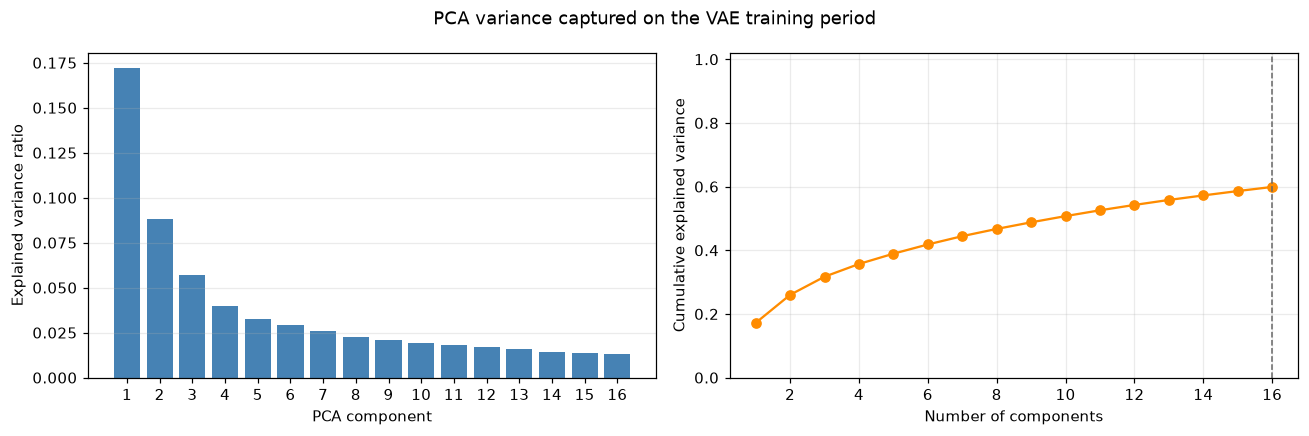

In [31]:
component_numbers = np.arange(1, N_COMPONENTS + 1)
ratios = pca["explained_variance_ratio"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(component_numbers, ratios, color="steelblue")
axes[0].set(xlabel="PCA component", ylabel="Explained variance ratio")
axes[0].set_xticks(component_numbers)
axes[0].grid(axis="y", alpha=0.25)
axes[1].plot(component_numbers, np.cumsum(ratios), marker="o", color="darkorange")
axes[1].axvline(N_COMPONENTS, color="0.4", linestyle="--", linewidth=1)
axes[1].set(xlabel="Number of components", ylabel="Cumulative explained variance")
axes[1].set_ylim(0, 1.02)
axes[1].grid(alpha=0.25)
fig.suptitle("PCA variance captured on the VAE training period")
fig.tight_layout()
plt.show()

### PCA score space coloured by ONI category

This is the PCA equivalent of the VAE latent-space plots. Unlike VAE coordinates, PCA components are ordered by explained variance and have a linear interpretation as spatial SST patterns.

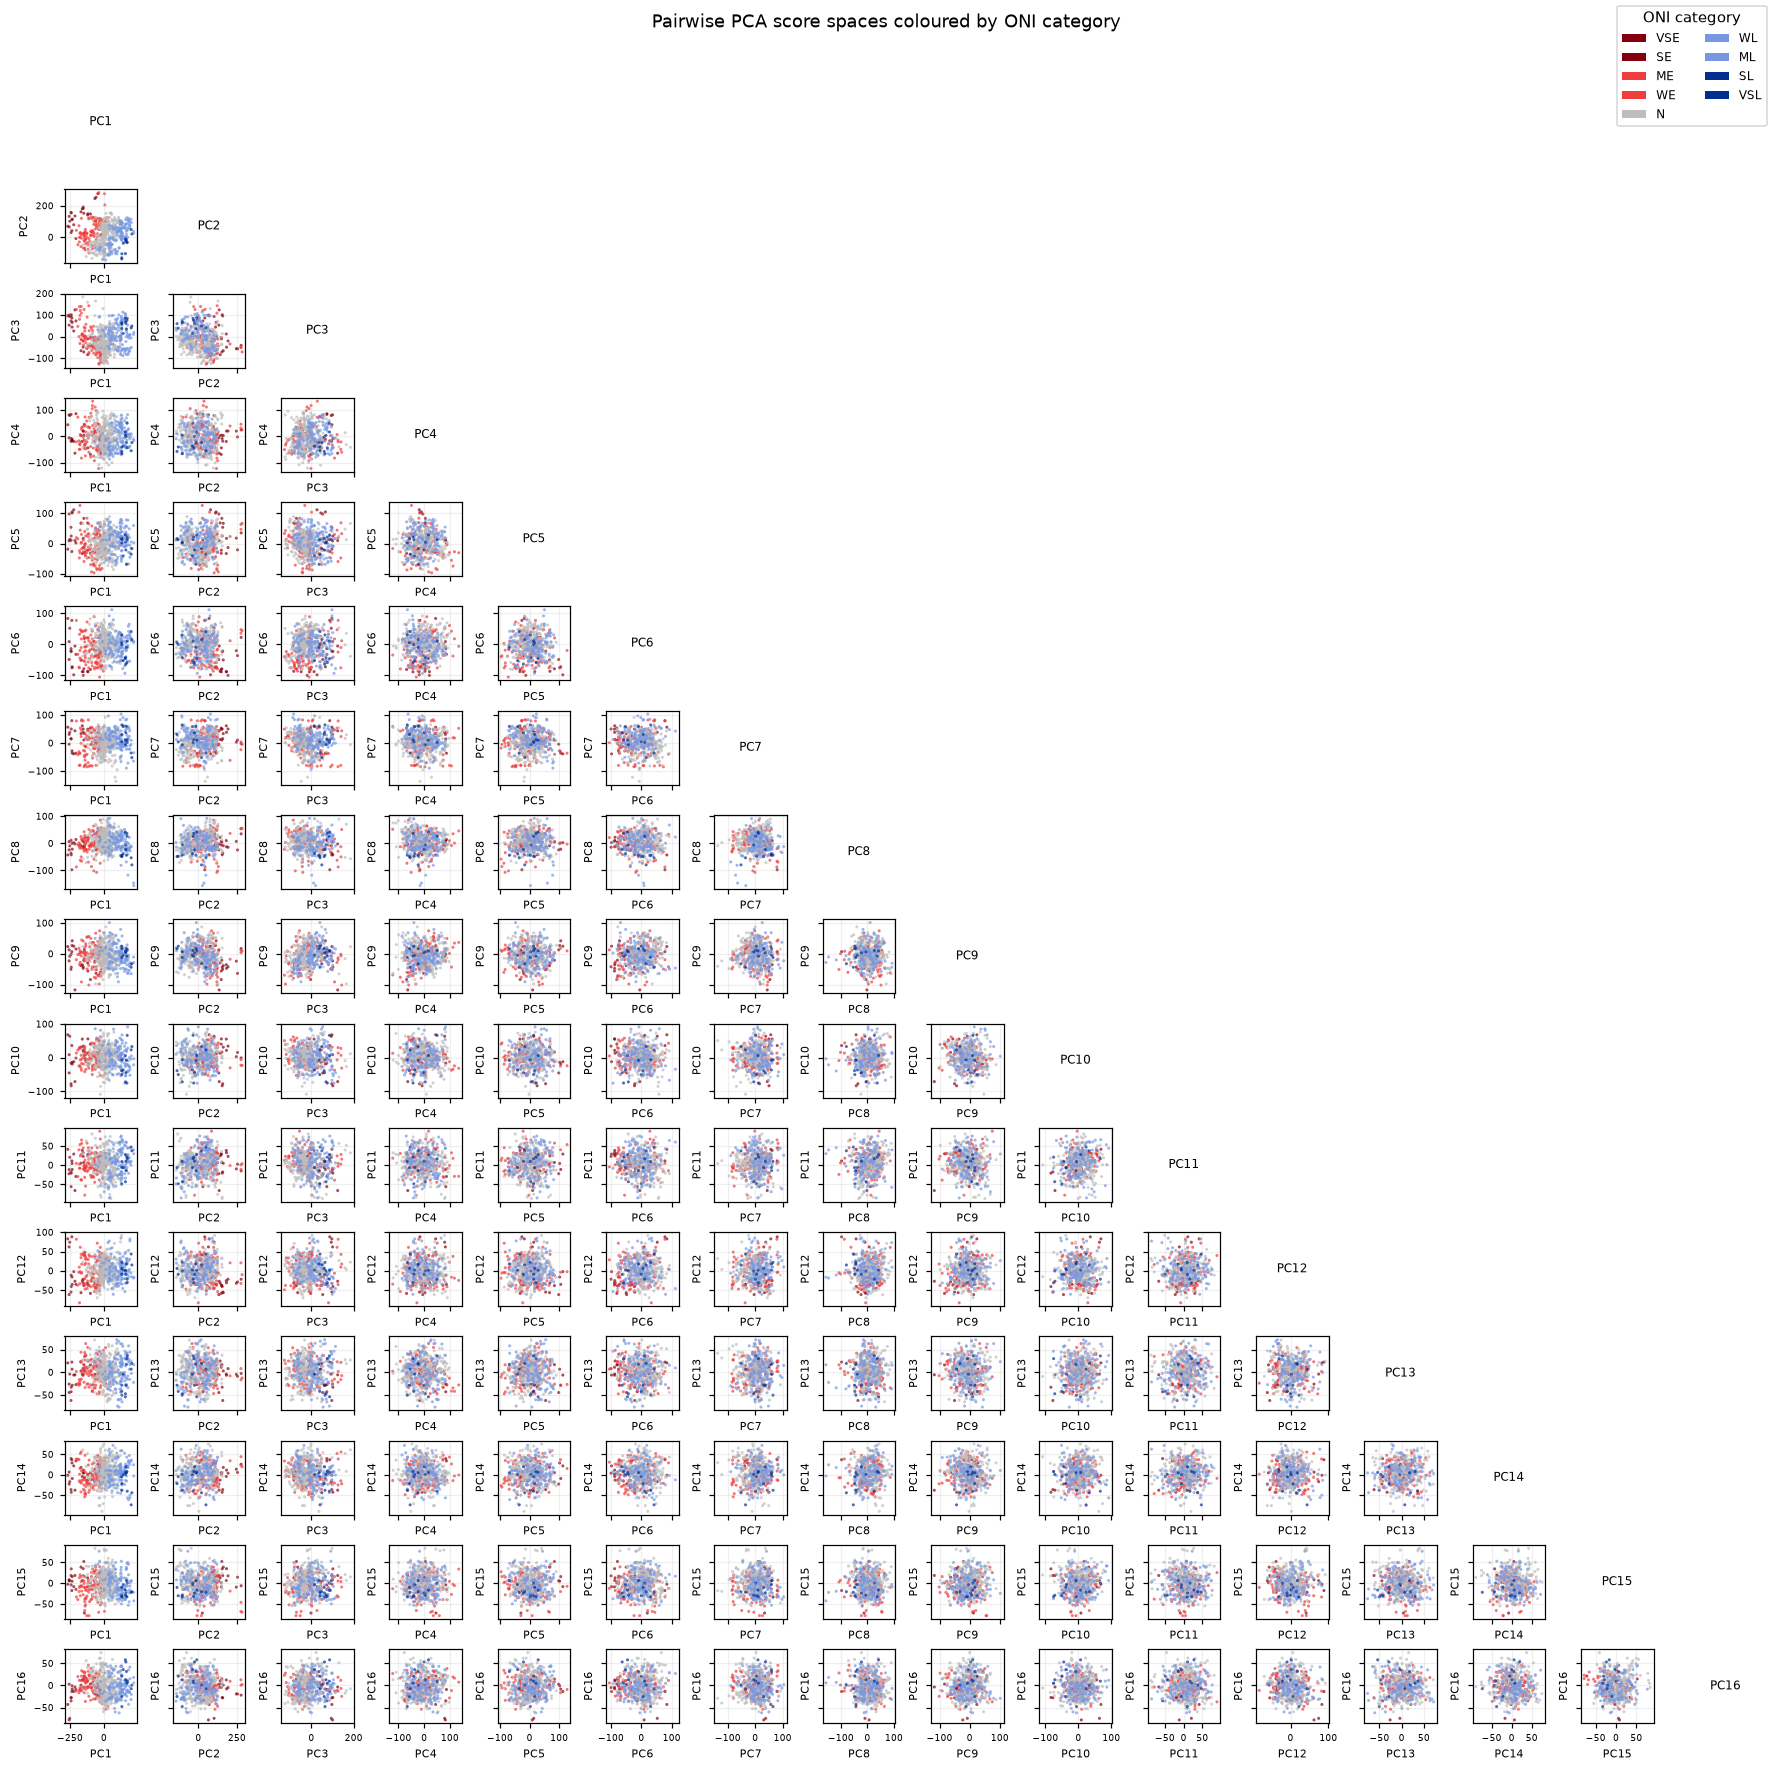

Matched 528 of 528 months to ONI categories


In [32]:
dates = sst_anomaly.time.dt.strftime("%Y-%m-%d").values
categories = np.array([oni_by_date.get(date, "Unlabelled") for date in dates])
matched = categories != "Unlabelled"

fig, axes = plt.subplots(N_COMPONENTS, N_COMPONENTS, figsize=(16, 16), sharex="col", sharey="row", squeeze=False)
for first, second in combinations(range(N_COMPONENTS), 2):
    axis = axes[second, first]
    for category, colour in CATEGORY_COLOURS.items():
        selected = matched & (categories == category)
        axis.scatter(scores[selected, first], scores[selected, second], color=colour, s=4, alpha=0.7, edgecolors="none", rasterized=True)
    axis.set_xlabel(f"PC{first + 1}", fontsize=7)
    axis.set_ylabel(f"PC{second + 1}", fontsize=7)
    axis.tick_params(labelsize=6)
    axis.grid(alpha=0.2)
for index in range(N_COMPONENTS):
    axes[index, index].text(0.5, 0.5, f"PC{index + 1}", ha="center", va="center", fontsize=8, transform=axes[index, index].transAxes)
    axes[index, index].set_axis_off()
for first in range(N_COMPONENTS):
    for second in range(first + 1, N_COMPONENTS):
        axes[first, second].set_visible(False)
fig.legend(handles=[Patch(facecolor=colour, label=category) for category, colour in CATEGORY_COLOURS.items()], title="ONI category", loc="upper right", ncol=2, fontsize=8)
fig.suptitle("Pairwise PCA score spaces coloured by ONI category", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97), pad=0.3)
plt.show()
print(f"Matched {matched.sum()} of {len(matched)} months to ONI categories")

### A directly comparable two-dimensional view

For a simple visual comparison, use the same two-dimensional view for both methods: PCA uses `PC1` and `PC2`; the VAE notebook can use its selected `z` pair. The axes are not expected to match numerically because PCA and VAE learn different coordinate systems.

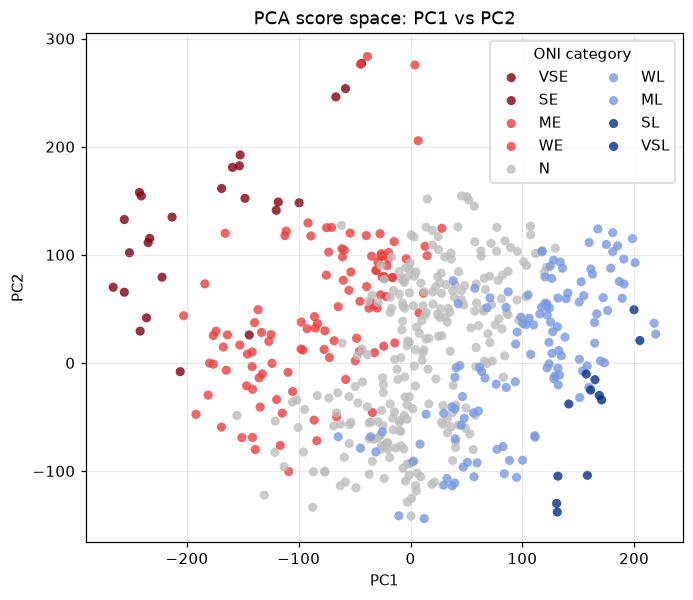

In [33]:
x_component, y_component = 0, 1
fig, axis = plt.subplots(figsize=(7, 6))
for category, colour in CATEGORY_COLOURS.items():
    selected = matched & (categories == category)
    axis.scatter(scores[selected, x_component], scores[selected, y_component], color=colour, label=category, alpha=0.8, edgecolors="none")
axis.set_xlabel(f"PC{x_component + 1}")
axis.set_ylabel(f"PC{y_component + 1}")
axis.set_title("PCA score space: PC1 vs PC2")
axis.legend(title="ONI category", ncol=2)
axis.grid(alpha=0.25)
plt.show()


### PCA reconstruction of one SST anomaly field

PCA reconstruction is the mean field plus a linear combination of the retained spatial components. This is comparable to the VAE decode panel, but PCA has no sampling step and no nonlinear decoder.

In [34]:
indices

array([214., 240., 396.])

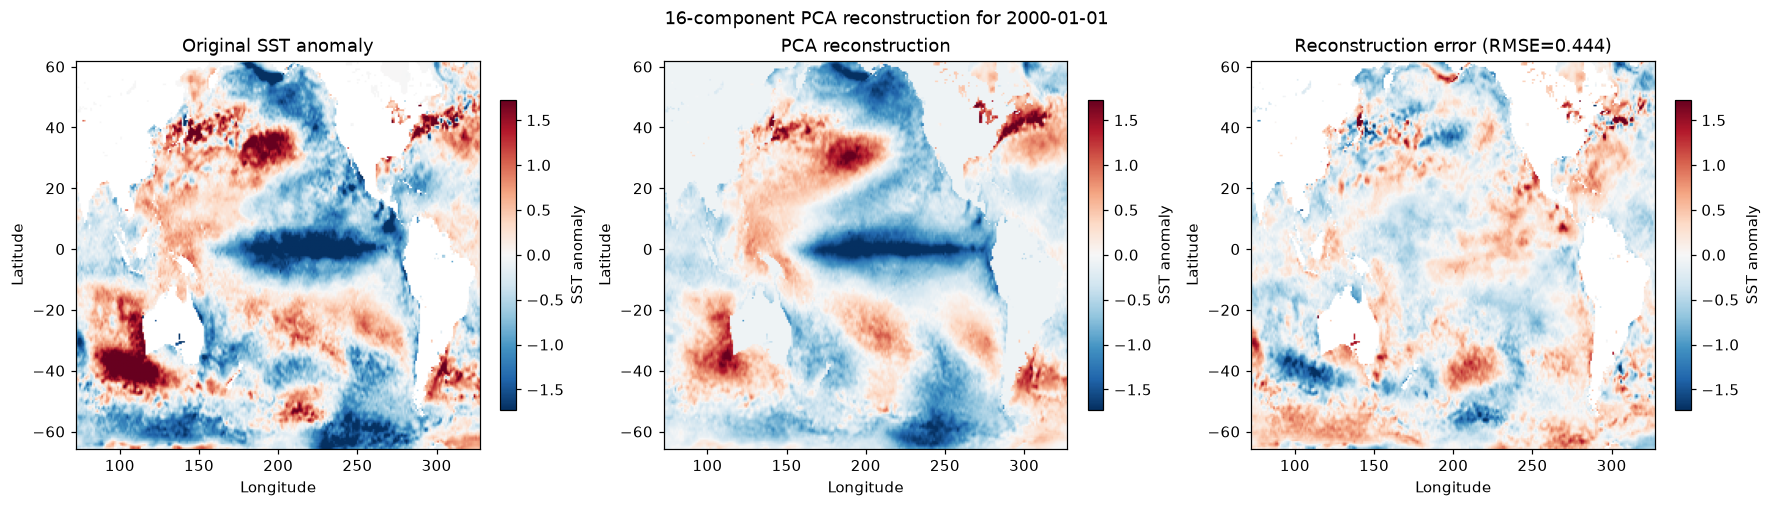

RMSE over finite ocean cells: 0.4435


In [35]:
sample_index = 240
if not 0 <= sample_index < n_months:
    raise ValueError(f"sample_index must be between 0 and {n_months - 1}")

original_anomaly = raw_values[sample_index]
reconstructed = reconstructed_anomaly[sample_index]
error = reconstructed - original_anomaly
valid = np.isfinite(original_anomaly)
rmse = float(np.sqrt(np.mean(error[valid] ** 2)))
date = str(sst_anomaly.time.isel(time=sample_index).values)[:10]

image_extent = [float(sst_anomaly.longitude.min()), float(sst_anomaly.longitude.max()), float(sst_anomaly.latitude.min()), float(sst_anomaly.latitude.max())]
plots = [(original_anomaly, "Original SST anomaly"), (reconstructed, "PCA reconstruction"), (error, f"Reconstruction error (RMSE={rmse:.3f})")]
common_limit = np.nanpercentile(np.concatenate([np.abs(image[valid]).ravel() for image, _ in plots]), 98)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for axis, (image, title) in zip(axes, plots):
    im = axis.imshow(image, origin="upper", extent=image_extent, cmap="RdBu_r", vmin=-common_limit, vmax=common_limit, aspect="auto")
    axis.set_title(title)
    axis.set_xlabel("Longitude")
    axis.set_ylabel("Latitude")
    fig.colorbar(im, ax=axis, shrink=0.8, label="SST anomaly")
fig.suptitle(f"{N_COMPONENTS}-component PCA reconstruction for {date}")
plt.show()
print(f"RMSE over finite ocean cells: {rmse:.4f}")


In [36]:
pca_rmses = np.array([])
for i in indices:
    if not 0 <= sample_index < n_months:
        raise ValueError(f"sample_index must be between 0 and {n_months - 1}")
    else:
        original_anomaly = raw_values[sample_index]
        reconstructed = reconstructed_anomaly[sample_index]
        error = reconstructed - original_anomaly
        valid = np.isfinite(original_anomaly)
        rmse = float(np.sqrt(np.mean(error[valid] ** 2)))
        pca_rmses = np.append(pca_rmses, rmse)


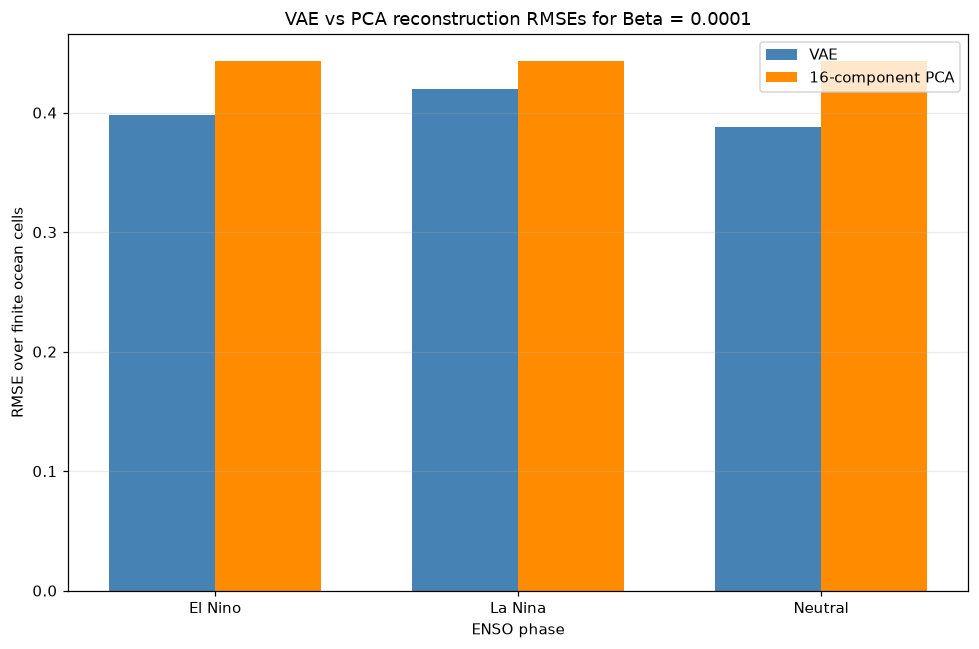

In [37]:
# Convert ONI's detailed categories into the three broad labels
def enso_label(category):
    if category in {"VSE", "SE", "ME", "WE"}:
        return "El Nino"
    if category == "N":
        return "Neutral"
    if category in {"WL", "ML", "SL", "VSL"}:
        return "La Nina"
    return "Unlabelled"


# Get the ONI category for each sample used to calculate the RMSEs
sample_dates = [
    str(sst_anomaly.time.isel(time=int(sample_index)).values)[:10]
    for sample_index in indices
]

enso_labels = [
    enso_label(oni_by_date.get(date, "Unlabelled"))
    for date in sample_dates
]

# Make sure all arrays have matching lengths
if not (len(indices) == len(rmses) == len(pca_rmses) == len(enso_labels)):
    raise ValueError("indices, rmses, pca_rmses, and enso_labels must have equal lengths")

x = np.arange(len(indices))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    x - width / 2,
    rmses,
    width,
    color="steelblue",
    label="VAE",
)

ax.bar(
    x + width / 2,
    pca_rmses,
    width,
    color="darkorange",
    label=f"{N_COMPONENTS}-component PCA",
)

ax.set_xlabel("ENSO phase")
ax.set_ylabel("RMSE over finite ocean cells")
ax.set_title(f"VAE vs PCA reconstruction RMSEs for Beta = {BETA}")
ax.set_xticks(x)
ax.set_xticklabels(enso_labels)
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()